<a href="https://colab.research.google.com/github/saradadevivalina/banking77-intent-classifier/blob/main/banking77_intent_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer-Support Intent Classification with DistilBERT (Banking77)

**Goal:** route customer-support messages to the right intent automatically, e.g. *"I lost my card"* → `lost_or_stolen_card`.

**Dataset:** [Banking77](https://github.com/PolyAI-LDN/task-specific-datasets) (PolyAI): about 13,000 real online-banking customer queries labelled with **77 fine-grained intents**.

**Approach:**
1. Exploratory look at the data (class balance, message length)
2. **Baseline:** TF-IDF + Logistic Regression (classical ML)
3. **Deep learning:** fine-tune the Transformer **DistilBERT** (`distilbert-base-uncased`) with Hugging Face `Trainer`
4. Evaluate both on the held-out test set with **accuracy** and **macro-F1** (every intent counts equally)
5. **Error analysis:** which intents get confused, and why

> **Before running:** in Colab, go to **Runtime → Change runtime type → T4 GPU**, then **Runtime → Run all**. Fine-tuning takes about 5–10 minutes on the free GPU.

## 1. Setup

In [1]:
# Colab already includes torch, transformers, scikit-learn and pandas.
# accelerate is needed by the Hugging Face Trainer.
!pip install -q accelerate

import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)
if device == "cpu":
    print("WARNING: no GPU found. Go to Runtime -> Change runtime type -> T4 GPU, then run again.")

Using device: cuda


## 2. Load the data
The official train/test CSV files are loaded straight from PolyAI's GitHub repository.

In [2]:
BASE = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data"
train_full = pd.read_csv(f"{BASE}/train.csv")   # columns: text, category
test_df = pd.read_csv(f"{BASE}/test.csv")
# Name the two columns explicitly: the message text and its intent label
train_full.columns = ["text", "category"]
test_df.columns = ["text", "category"]

print("Train rows:", len(train_full), "| Test rows:", len(test_df))
print("Number of intents:", train_full["category"].nunique())
train_full.sample(5, random_state=SEED)

Train rows: 10003 | Test rows: 3080
Number of intents: 77


,text,category
6883,Is it possible for me to change my PIN number?,change_pin
5836,I'm not sure why my card didn't work,declined_card_payment
8601,I don't think my top up worked,top_up_failed
2545,Can you explain why my payment was charged a fee?,card_payment_fee_charged
8697,How long does a transfer from a UK account tak...,balance_not_updated_after_bank_transfer


## 3. Exploratory data analysis

Examples per intent: min=35, median=127, max=187
Words per message: mean=11.9, 95th percentile=29, max=79


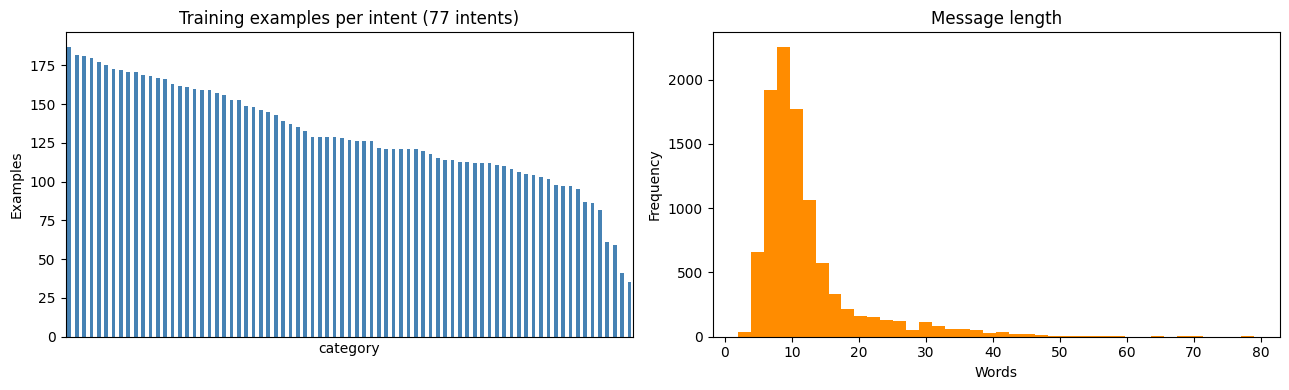

In [3]:
counts = train_full["category"].value_counts()
print(f"Examples per intent: min={counts.min()}, median={int(counts.median())}, max={counts.max()}")

lengths = train_full["text"].str.split().str.len()
print(f"Words per message: mean={lengths.mean():.1f}, 95th percentile={lengths.quantile(0.95):.0f}, max={lengths.max()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Training examples per intent (77 intents)")
axes[0].set_xticks([])
axes[0].set_ylabel("Examples")
lengths.plot(kind="hist", bins=40, ax=axes[1], color="darkorange")
axes[1].set_title("Message length")
axes[1].set_xlabel("Words")
plt.tight_layout(); plt.show()

**Reading the EDA:** the classes are *moderately* imbalanced, so **macro-F1** (the average F1 across all 77 intents) is reported alongside accuracy. That way rare intents count as much as common ones. Messages are short, so a maximum sequence length of 64 tokens is enough for the Transformer.

## 4. Encode labels and create a validation split
The official test set is kept untouched for the final comparison. A stratified 10% of the training data is held out for validation during fine-tuning.

In [4]:
labels = sorted(train_full["category"].unique())
label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}

train_full["label"] = train_full["category"].map(label2id)
test_df["label"] = test_df["category"].map(label2id)

train_df, val_df = train_test_split(
    train_full, test_size=0.10, stratify=train_full["label"], random_state=SEED
)
print("Train:", len(train_df), "| Validation:", len(val_df), "| Test:", len(test_df))

Train: 9002 | Validation: 1001 | Test: 3080


## 5. Baseline: TF-IDF + Logistic Regression
A strong classical baseline. The Transformer has to beat this for the extra complexity to be worth it.

In [5]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(train_df["text"])   # fit on training data only (no leakage)
X_test = tfidf.transform(test_df["text"])

baseline = LogisticRegression(max_iter=2000, C=10)
baseline.fit(X_train, train_df["label"])
baseline_pred = baseline.predict(X_test)

baseline_acc = accuracy_score(test_df["label"], baseline_pred)
baseline_f1 = f1_score(test_df["label"], baseline_pred, average="macro")
print(f"Baseline TF-IDF + LogReg  ->  accuracy: {baseline_acc:.4f} | macro-F1: {baseline_f1:.4f}")

Baseline TF-IDF + LogReg  ->  accuracy: 0.8851 | macro-F1: 0.8854


## 6. Fine-tune DistilBERT
`distilbert-base-uncased` is a smaller, faster version of BERT (about 66M parameters). A classification head with 77 outputs is added on top and the whole network is fine-tuned on our data.

In [7]:
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    DataCollatorWithPadding, TrainingArguments, Trainer,
)

MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=64)

def to_dataset(df):
    return Dataset.from_pandas(df[["text", "label"]].reset_index(drop=True)).map(tokenize, batched=True)

train_ds, val_ds, test_ds = to_dataset(train_df), to_dataset(val_df), to_dataset(test_df)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(labels), id2label=id2label, label2id=label2id
)

def compute_metrics(eval_pred):
    logits, y_true = eval_pred
    y_pred = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }

args = TrainingArguments(
    output_dir="distilbert-banking77",
    num_train_epochs=4,
    learning_rate=5e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    warmup_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,       # keep the epoch with the best validation macro-F1
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    fp16=torch.cuda.is_available(),    # faster mixed-precision training on the GPU
    logging_steps=50,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)
trainer.train()

Map:   0%|          | 0/9002 [00:00<?, ? examples/s]

Map:   0%|          | 0/1001 [00:00<?, ? examples/s]

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.972928,1.308374,0.785215,0.738180
2,0.579425,0.496285,0.885115,0.876912
3,0.321883,0.359410,0.908092,0.912798
4,0.173581,0.329668,0.914086,0.916559


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1128, training_loss=1.0987876082988495, metrics={'train_runtime': 111.2588, 'train_samples_per_second': 323.642, 'train_steps_per_second': 10.139, 'total_flos': 432156029442048.0, 'train_loss': 1.0987876082988495, 'epoch': 4.0})

### Training curve (validation metrics per epoch)

 epoch  eval_loss  eval_accuracy  eval_macro_f1
   1.0   1.308374       0.785215       0.738180
   2.0   0.496285       0.885115       0.876912
   3.0   0.359410       0.908092       0.912798
   4.0   0.329668       0.914086       0.916559


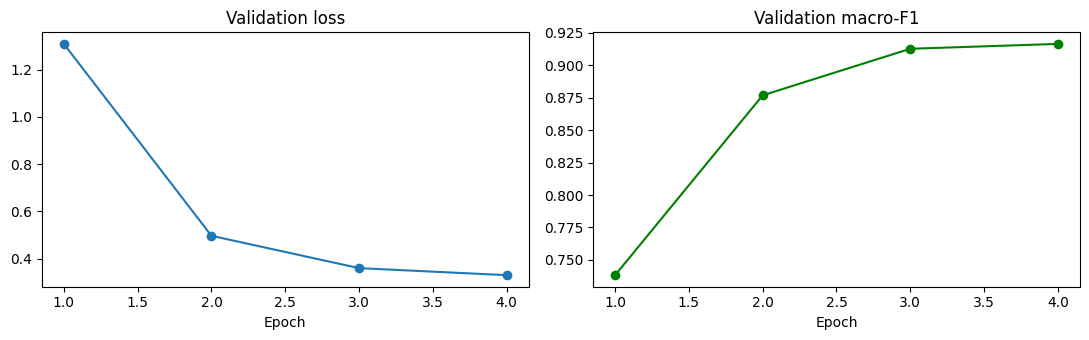

In [8]:
history = pd.DataFrame(trainer.state.log_history)
val_hist = history.dropna(subset=["eval_macro_f1"])[["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1"]]
print(val_hist.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(val_hist["epoch"], val_hist["eval_loss"], marker="o"); ax[0].set_title("Validation loss"); ax[0].set_xlabel("Epoch")
ax[1].plot(val_hist["epoch"], val_hist["eval_macro_f1"], marker="o", color="green"); ax[1].set_title("Validation macro-F1"); ax[1].set_xlabel("Epoch")
plt.tight_layout(); plt.show()

## 7. Final evaluation on the held-out test set

In [9]:
test_output = trainer.predict(test_ds)
bert_pred = np.argmax(test_output.predictions, axis=-1)

bert_acc = accuracy_score(test_df["label"], bert_pred)
bert_f1 = f1_score(test_df["label"], bert_pred, average="macro")

results = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression (baseline)", "DistilBERT fine-tuned"],
    "Test accuracy": [baseline_acc, bert_acc],
    "Test macro-F1": [baseline_f1, bert_f1],
}).round(4)
print(results.to_string(index=False))
print(f"\nImprovement over baseline: +{(bert_acc - baseline_acc) * 100:.1f} accuracy points, "
      f"+{(bert_f1 - baseline_f1) * 100:.1f} macro-F1 points")

                                  Model  Test accuracy  Test macro-F1
TF-IDF + Logistic Regression (baseline)         0.8851         0.8854
                  DistilBERT fine-tuned         0.9198         0.9198

Improvement over baseline: +3.5 accuracy points, +3.4 macro-F1 points


## 8. Error analysis
Which intents does the fine-tuned model find hardest, and which pairs does it confuse?

In [10]:
report = classification_report(test_df["label"], bert_pred, target_names=labels, output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.iloc[:len(labels)][["precision", "recall", "f1-score", "support"]]
print("5 hardest intents (lowest F1):")
print(per_class.sort_values("f1-score").head(5).round(3).to_string())

cm = confusion_matrix(test_df["label"], bert_pred)
np.fill_diagonal(cm, 0)
pairs = [(cm[i, j], id2label[i], id2label[j]) for i in range(len(labels)) for j in range(len(labels)) if cm[i, j] > 0]
pairs.sort(reverse=True)
print("\nMost frequent confusions (true -> predicted):")
for n, true_label, pred_label in pairs[:8]:
    print(f"  {n:>2} x  {true_label}  ->  {pred_label}")

5 hardest intents (lowest F1):
                                         precision  recall  f1-score  support
why_verify_identity                          0.763   0.725     0.744     40.0
balance_not_updated_after_bank_transfer      0.789   0.750     0.769     40.0
verify_my_identity                           0.750   0.825     0.786     40.0
pending_transfer                             0.838   0.775     0.805     40.0
topping_up_by_card                           0.861   0.775     0.816     40.0

Most frequent confusions (true -> predicted):
  10 x  why_verify_identity  ->  verify_my_identity
   5 x  verify_my_identity  ->  why_verify_identity
   5 x  fiat_currency_support  ->  exchange_via_app
   4 x  wrong_exchange_rate_for_cash_withdrawal  ->  card_payment_wrong_exchange_rate
   4 x  get_disposable_virtual_card  ->  getting_virtual_card
   4 x  card_delivery_estimate  ->  card_arrival
   4 x  card_arrival  ->  card_delivery_estimate
   4 x  balance_not_updated_after_bank_transfer  -> 

In [11]:
# A few misclassified test messages, to see WHY the model got them wrong
wrong = test_df.assign(predicted=[id2label[p] for p in bert_pred])
wrong = wrong[wrong["label"] != bert_pred][["text", "category", "predicted"]]
print(f"Misclassified: {len(wrong)} of {len(test_df)} test messages")
wrong.sample(min(8, len(wrong)), random_state=SEED)

Misclassified: 247 of 3080 test messages


,text,category,predicted
453,Is a copy of the police report necessary for c...,lost_or_stolen_card,balance_not_updated_after_cheque_or_cash_deposit
93,Is it a good time to exchange?,exchange_rate,exchange_via_app
2300,What are your policies for card transfers?,failed_transfer,topping_up_by_card
1166,Do I have to do the identity check?,why_verify_identity,verify_my_identity
1866,I would like to know why my payment is still p...,pending_transfer,pending_card_payment
2252,Is GBP a supported currency?,receiving_money,exchange_via_app
2503,can I have a non virtual card?,order_physical_card,getting_virtual_card
1331,Where's the money that got charged to my card?...,topping_up_by_card,transfer_fee_charged


**Interpreting the errors:** most mistakes are between intents that are genuinely close in meaning (for example different kinds of card or transfer problems). Often the message itself is ambiguous even for a human agent. A production system could handle these with a confidence threshold that hands low-confidence messages to a human, or asks the customer a clarifying question.

## 9. Try the model

In [12]:
def predict_intent(message, top_k=3):
    inputs = tokenizer(message, return_tensors="pt", truncation=True, max_length=64).to(trainer.model.device)
    with torch.no_grad():
        probs = torch.softmax(trainer.model(**inputs).logits, dim=-1)[0]
    top = torch.topk(probs, top_k)
    return [(id2label[i.item()], round(p.item(), 3)) for p, i in zip(top.values, top.indices)]

for msg in [
    "I lost my card yesterday, what should I do?",
    "Why was I charged twice for the same purchase?",
    "My transfer still hasn't arrived after 3 days",
    "Can I change my PIN at an ATM?",
]:
    print(msg, "->", predict_intent(msg))

I lost my card yesterday, what should I do? -> [('lost_or_stolen_card', 0.925), ('card_arrival', 0.01), ('compromised_card', 0.008)]
Why was I charged twice for the same purchase? -> [('transaction_charged_twice', 0.979), ('transfer_fee_charged', 0.002), ('card_payment_fee_charged', 0.001)]
My transfer still hasn't arrived after 3 days -> [('transfer_not_received_by_recipient', 0.827), ('balance_not_updated_after_bank_transfer', 0.123), ('pending_transfer', 0.017)]
Can I change my PIN at an ATM? -> [('change_pin', 0.966), ('top_up_by_cash_or_cheque', 0.006), ('get_physical_card', 0.004)]


## 10. Save the model

In [13]:
trainer.save_model("distilbert-banking77-final")
tokenizer.save_pretrained("distilbert-banking77-final")
print("Saved to ./distilbert-banking77-final")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to ./distilbert-banking77-final


## Summary

| | Test accuracy | Test macro-F1 |
|---|---|---|
| TF-IDF + Logistic Regression | *see section 7* | *see section 7* |
| DistilBERT (fine-tuned) | *see section 7* | *see section 7* |

**Takeaways:** fine-tuning a pretrained Transformer captures the *meaning* of a message rather than just its words, which matters when 77 intents differ by small details. The classical baseline is still strong, cheap and explainable, which is why it is the benchmark to beat. The remaining errors are mostly between near-duplicate intents.